### Experimentos extras

Dois experimentos simples que complementam os notebooks principais, usando as mesmas classes `QLearning` e `Sarsa` de `agentes.py`:

1. **Decaimento do ε:** o que muda quando o agente explora por mais tempo.
2. **Intensidade da chuva:** como o desempenho muda com `rainy_probability` de 0,4 a 1,0.

Os parâmetros são os mesmos dos notebooks principais (α=0,1, γ=0,99, ε de 0,7 até 0,05) e todas as execuções usam seed, então os resultados se repetem. O notebook leva cerca de 5 minutos para rodar.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agentes import QLearning, Sarsa, criar_env, avaliar_q_table

os.makedirs('results_experimentos', exist_ok=True)

PARAMS = dict(alpha=0.1, gamma=0.99, epsilon=0.7, epsilon_min=0.05)


def moving_average(x, window=100):
    return np.convolve(x, np.ones(window) / window, mode='valid')


def primeiro_episodio(rewards, limiar, window=100):
    acima = np.where(moving_average(np.array(rewards), window) >= limiar)[0]
    return int(acima[0] + window) if len(acima) > 0 else None

### 1. Decaimento do ε

Nos notebooks principais o ε é multiplicado por 0,99 a cada episódio e chega ao mínimo (0,05) no episódio 264. Aqui o Q-learning sem chuva é treinado (5 execuções de 10.000 episódios) com três decaimentos diferentes:

| epsilon_dec | ε chega a 0,05 no episódio |
|---|---|
| 0,99 (original) | 264 |
| 0,999 | ~2600 |
| 0,9995 | ~5300 |

Quanto mais perto de 1, mais devagar o ε cai e mais tempo o agente passa explorando.

In [2]:
DECAIMENTOS = [0.99, 0.999, 0.9995]
N_RUNS = 5

rewards_eps = {}
linhas = []
for dec in DECAIMENTOS:
    rewards_eps[dec] = []
    for run in range(N_RUNS):
        ag = QLearning(criar_env(), episodes=10_000, seed=run, epsilon_dec=dec, **PARAMS)
        ag.train(log_every=0)
        rewards_eps[dec].append(ag.rewards_per_episode)
        teste = avaliar_q_table(ag.q_table)
        linhas.append({'epsilon_dec': str(dec), 'Execução': run + 1,
                       'Reward ≥ 0 no treino (episódio)': primeiro_episodio(ag.rewards_per_episode, 0),
                       'Teste: timesteps (média)': teste['Timesteps (média)'],
                       'Teste: reward médio': teste['Reward médio']})

tabela_eps = pd.DataFrame(linhas).groupby('epsilon_dec', sort=False).mean(numeric_only=True).drop(columns='Execução')
tabela_eps.round(2)

,Reward ≥ 0 no treino (episódio),Teste: timesteps (média),Teste: reward médio
epsilon_dec,,,
0.99,949.6,13.31,7.69
0.999,1699.0,13.31,7.69
0.9995,3172.8,13.31,7.69


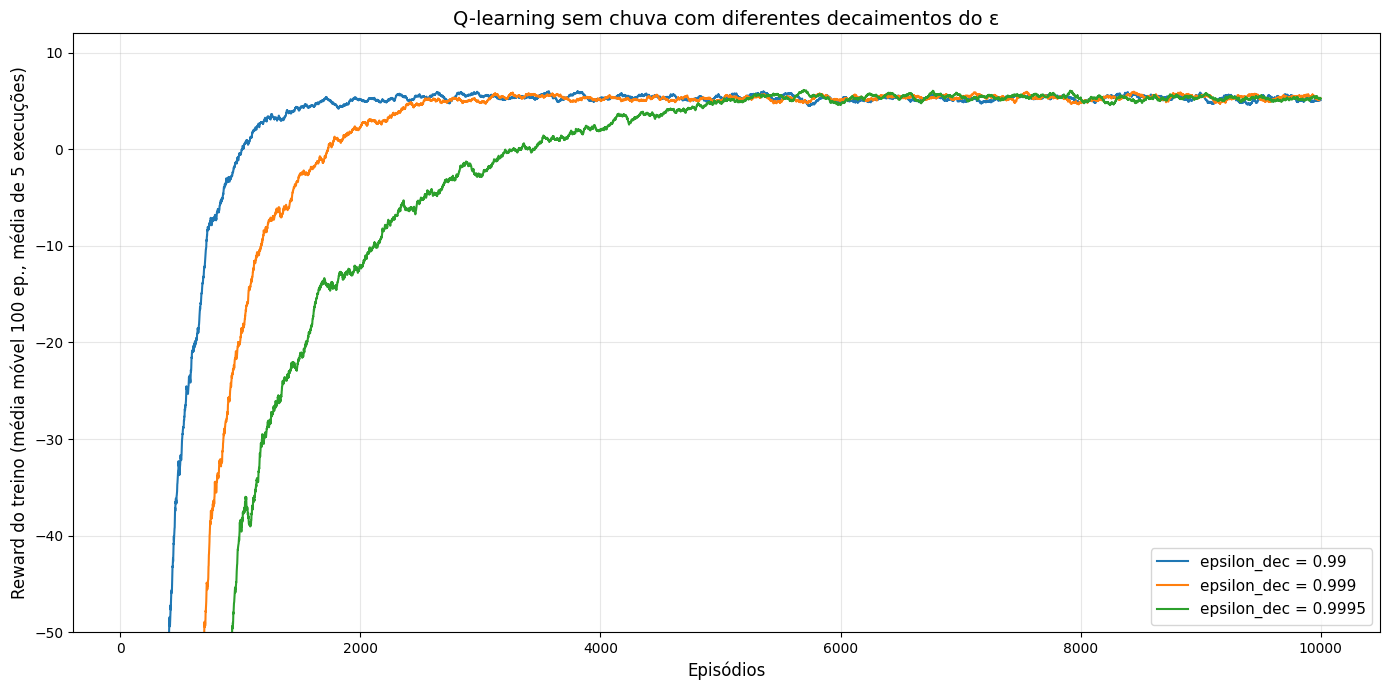

In [3]:
plt.figure(figsize=(14, 7))
for dec, rewards in rewards_eps.items():
    curva = np.mean([moving_average(np.array(r)) for r in rewards], axis=0)
    plt.plot(np.arange(len(curva)) + 100, curva, linewidth=1.5, label=f'epsilon_dec = {dec}')

plt.ylim(-50, 12)
plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward do treino (média móvel 100 ep., média de 5 execuções)', fontsize=12)
plt.title('Q-learning sem chuva com diferentes decaimentos do ε', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_experimentos/decaimento_epsilon.jpg', dpi=120)
plt.show()

#### Discussão - Decaimento do ε

| epsilon_dec | Reward ≥ 0 no treino (episódio médio) | Teste: timesteps | Teste: reward médio |
|---|---|---|---|
| 0,99 (original) | 950 | 13,31 | 7,69 |
| 0,999 | 1699 | 13,31 | 7,69 |
| 0,9995 | 3173 | 13,31 | 7,69 |

- **Explorar mais deixa a curva do treino mais lenta.** Com 0,9995, o reward do treino só fica positivo por volta do episódio 3173, contra 950 no original. Isso acontece porque o agente passa muito mais tempo fazendo ações aleatórias, que gastam passos e às vezes dão -10.
- **No final, os três aprendem a mesma coisa.** Depois que o ε chega no mínimo, as curvas se juntam, e no teste (sem ações aleatórias) os três decaimentos dão exatamente o mesmo resultado: 13,31 passos e reward 7,69.

**Conclusão:** no Taxi, o decaimento original (0,99) já é suficiente. O ambiente é pequeno (500 estados), então pouca exploração basta, e explorar por mais tempo só atrasa o treino.

### 2. Intensidade da chuva

`rainy_probability` é a chance de o táxi ir para onde quer; no resto das vezes ele desvia para um dos lados. Nos notebooks principais usamos 0,6. Aqui o Q-learning e o Sarsa são treinados (3 execuções de 20.000 episódios cada) com 0,4, 0,6, 0,8 e 1,0. Com 1,0 o táxi nunca desvia, então é igual ao ambiente sem chuva.

O teste é o mesmo dos notebooks principais: 100 episódios sem ações aleatórias, com limite de 200 passos.

In [4]:
PROBS = [0.4, 0.6, 0.8, 1.0]
N_RUNS_CHUVA = 3

linhas = []
for p in PROBS:
    chuva = dict(is_rainy=True, rainy_probability=p)
    for nome, Classe in [('Q-learning', QLearning), ('Sarsa', Sarsa)]:
        for run in range(N_RUNS_CHUVA):
            ag = Classe(criar_env(**chuva), episodes=20_000, seed=run, epsilon_dec=0.99, **PARAMS)
            ag.train(log_every=0)
            teste = avaliar_q_table(ag.q_table, **chuva)
            linhas.append({'rainy_probability': p, 'Algoritmo': nome, 'Execução': run + 1,
                           'Timesteps (média)': teste['Timesteps (média)'],
                           'Reward médio': teste['Reward médio'],
                           'Não terminou': teste['Não terminou']})

resultados_chuva = pd.DataFrame(linhas)
tabela_chuva = resultados_chuva.groupby(['rainy_probability', 'Algoritmo']).agg(
    {'Timesteps (média)': 'mean', 'Reward médio': 'mean', 'Não terminou': 'sum'})
tabela_chuva.round(2)

Timesteps (média)  Reward médio  Não terminou
rainy_probability Algoritmo                                                
0.4               Q-learning              50.81        -30.02           3.0
                  Sarsa                   56.34        -36.18          12.0
0.6               Q-learning              25.73         -4.73           0.0
                  Sarsa                   27.16         -6.30           2.0
0.8               Q-learning              18.07          2.93           0.0
                  Sarsa                   18.12          2.88           0.0
1.0               Q-learning              13.31          7.69           0.0
                  Sarsa                   13.32          7.68           0.0

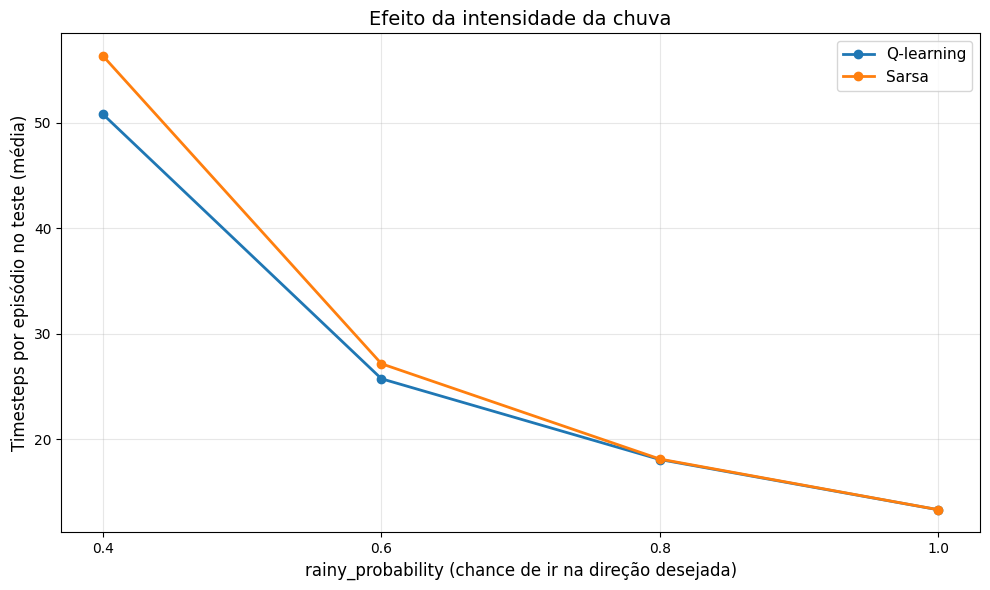

In [5]:
plt.figure(figsize=(10, 6))
for nome, cor in [('Q-learning', 'tab:blue'), ('Sarsa', 'tab:orange')]:
    passos = tabela_chuva.xs(nome, level='Algoritmo')['Timesteps (média)']
    plt.plot(PROBS, passos, marker='o', color=cor, linewidth=2, label=nome)

plt.xticks(PROBS)
plt.xlabel('rainy_probability (chance de ir na direção desejada)', fontsize=12)
plt.ylabel('Timesteps por episódio no teste (média)', fontsize=12)
plt.title('Efeito da intensidade da chuva', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_experimentos/intensidade_chuva.jpg', dpi=120)
plt.show()

#### Discussão - Intensidade da chuva

"Não terminou" é o total de episódios que passaram de 200 passos, somando as 3 execuções (300 episódios de teste).

| rainy_probability | Timesteps: Q-learning | Timesteps: Sarsa | Reward: Q-learning | Reward: Sarsa | Não terminou: Q-learning / Sarsa |
|---|---|---|---|---|---|
| 0,4 | 50,81 | 56,34 | -30,02 | -36,18 | 3 / 12 |
| 0,6 | 25,73 | 27,16 | -4,73 | -6,30 | 0 / 2 |
| 0,8 | 18,07 | 18,12 | 2,93 | 2,88 | 0 / 0 |
| 1,0 | 13,31 | 13,32 | 7,69 | 7,68 | 0 / 0 |

- **Quanto mais chuva, mais passos.** Sem desvio (1,0) a viagem leva ~13 passos; com 0,8 leva ~18, com 0,6 ~26 e com 0,4 ~51. Como cada passo custa -1, o reward cai junto: a meta de 8 só é alcançada sem desvio, com 0,8 o reward já cai para ~3 e com 0,6 fica negativo.
- **Com pouca chuva os dois algoritmos ficam iguais** (0,8 e 1,0).
- **Com chuva forte o Q-learning se sai melhor.** Com 0,4, o Sarsa fez 56 passos contra 51 do Q-learning e ficou preso em mais episódios (12 contra 3). Isso combina com o que vimos nos notebooks principais: o Sarsa aprende mais devagar, e quanto mais aleatório o ambiente, mais episódios ele precisaria para chegar no mesmo nível.

Os números com 0,6 ficam bem próximos dos do notebook não determinístico, que usa 5 execuções em vez de 3.

### Conclusões dos experimentos extras

1. **Decaimento do ε:** explorar por mais tempo atrasa a curva do treino, mas o agente aprende a mesma coisa no final. No Taxi, o decaimento de 0,99 já é suficiente.
2. **Intensidade da chuva:** quanto mais chuva, mais passos e menor o reward. Com pouca chuva Q-learning e Sarsa ficam iguais; com chuva forte o Q-learning se sai melhor, porque aprende mais rápido.